# DSCI 552 Homework 6
**Jun Jiang** · GitHub: `generalisjj-hub`

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, accuracy_score
from sklearn.model_selection import StratifiedKFold
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

warnings.filterwarnings('ignore', category=UserWarning)
DATA = Path('data') if Path('data').exists() else Path('../data')
SEED = 552
train = pd.read_csv(DATA / 'aps_failure_training_set.csv', skiprows=20, na_values='na')
test = pd.read_csv(DATA / 'aps_failure_test_set.csv', skiprows=20, na_values='na')
X_raw = train.drop(columns='class')
T_raw = test.drop(columns='class')
y = (train['class'] == 'pos').astype(int).to_numpy()
yt = (test['class'] == 'pos').astype(int).to_numpy()
# The assignment explicitly requires test-set statistics for test imputation.
train_imputer = SimpleImputer(strategy='median')
test_imputer = SimpleImputer(strategy='median')
X = train_imputer.fit_transform(X_raw).astype(np.float32)
T = test_imputer.fit_transform(T_raw).astype(np.float32)
features = X_raw.columns
print(f'Train: {X.shape}, test: {T.shape}; missing entries: {X_raw.isna().sum().sum():,} / {T_raw.isna().sum().sum():,}.')

Train: (60000, 170), test: (16000, 170); missing entries: 850,015 / 228,680.


## 1(a)–(b) Data preparation

Missing values can be addressed by deleting incomplete observations, mean/median imputation, or multivariate methods such as k-nearest-neighbor or iterative imputation. Since missing entries are common and the minority class is small, we use the median separately for each feature. As requested in the assignment, test medians come from the test set; training medians come from training data. Within cross-validation each fold's medians are fitted on that fold's training portion only. Sources: [scikit-learn imputation guide](https://scikit-learn.org/stable/modules/impute.html), [UCI data](https://archive.ics.uci.edu/dataset/421/aps+failure+at+scania+trucks).

The correlation-matrix indices follow the original 170 feature columns in dataset order (starting at 0).

In [2]:
counts = pd.DataFrame({'training': np.bincount(y, minlength=2), 'test': np.bincount(yt, minlength=2)}, index=['negative', 'positive'])
display(counts)
print(f"Training: {counts.loc['negative','training'] / counts.loc['positive','training']:.0f}:1 negative to positive; this is strongly imbalanced.")
filled = pd.DataFrame(X, columns=features)
cv = (filled.std(ddof=1) / filled.mean()).sort_values(ascending=False)
# Show all 170 coefficients in five side-by-side groups.
parts = []
for idx in np.array_split(np.arange(len(cv)), 5):
    parts.append(pd.DataFrame({'feature': cv.index[idx], 'CV': cv.iloc[idx].to_numpy()}).reset_index(drop=True))
display(pd.concat(parts, axis=1).round(3))
print('Top 13 features:', ', '.join(cv.head(13).index))

,training,test
negative,59000,15625
positive,1000,375


Training: 59:1 negative to positive; this is strongly imbalanced.


,feature,CV,feature,CV,feature,CV,feature,CV,feature,CV
0,cf_000,244.888000,ay_003,28.735001,be_000,6.847,cs_003,3.132,bb_000,2.405
1,co_000,244.507004,cn_000,26.336000,ba_008,6.831,ap_000,3.081,bv_000,2.405
2,ad_000,244.322998,ae_000,24.200001,cn_002,6.707,dd_000,3.057,bu_000,2.405
3,cs_009,237.931000,at_000,23.708000,cu_000,6.673,ck_000,3.056,cq_000,2.405
4,dh_000,123.216003,az_008,22.680000,cn_007,6.335,ay_006,3.053,ci_000,2.400
5,dj_000,117.494003,dq_000,22.030001,bz_000,6.314,az_005,3.035,ed_000,2.394
6,ag_000,92.917999,af_000,19.471001,db_000,6.259,ba_006,3.031,ag_006,2.357
7,as_000,87.333000,ai_000,18.204000,ag_008,6.221,bi_000,3.022,cn_005,2.345
8,ay_009,84.734001,ag_002,17.566000,av_000,6.006,ag_005,2.956,ds_000,2.320
9,ak_000,80.425003,az_007,16.229000,ee_009,5.692,du_000,2.918,ah_000,2.312


Top 13 features: cf_000, co_000, ad_000, cs_009, dh_000, dj_000, ag_000, as_000, ay_009, ak_000, az_009, ch_000, au_000


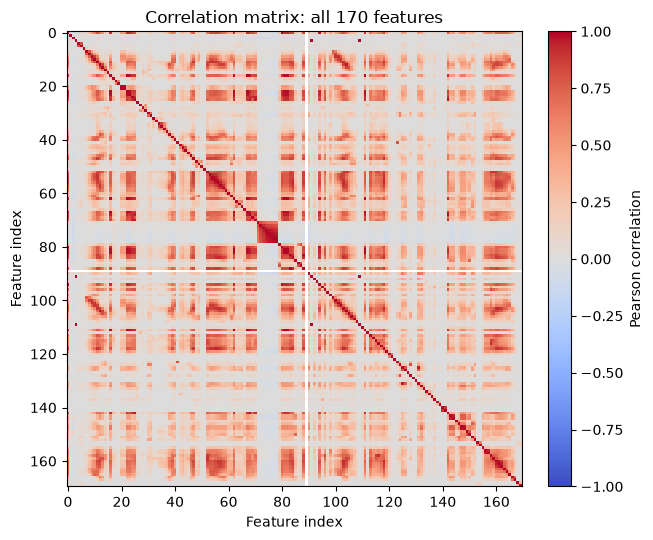

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(filled.corr(), cmap='coolwarm', vmin=-1, vmax=1, interpolation='nearest')
ax.set(title='Correlation matrix: all 170 features', xlabel='Feature index', ylabel='Feature index')
fig.colorbar(im, ax=ax, fraction=.045, label='Pearson correlation')
plt.tight_layout(); plt.show()

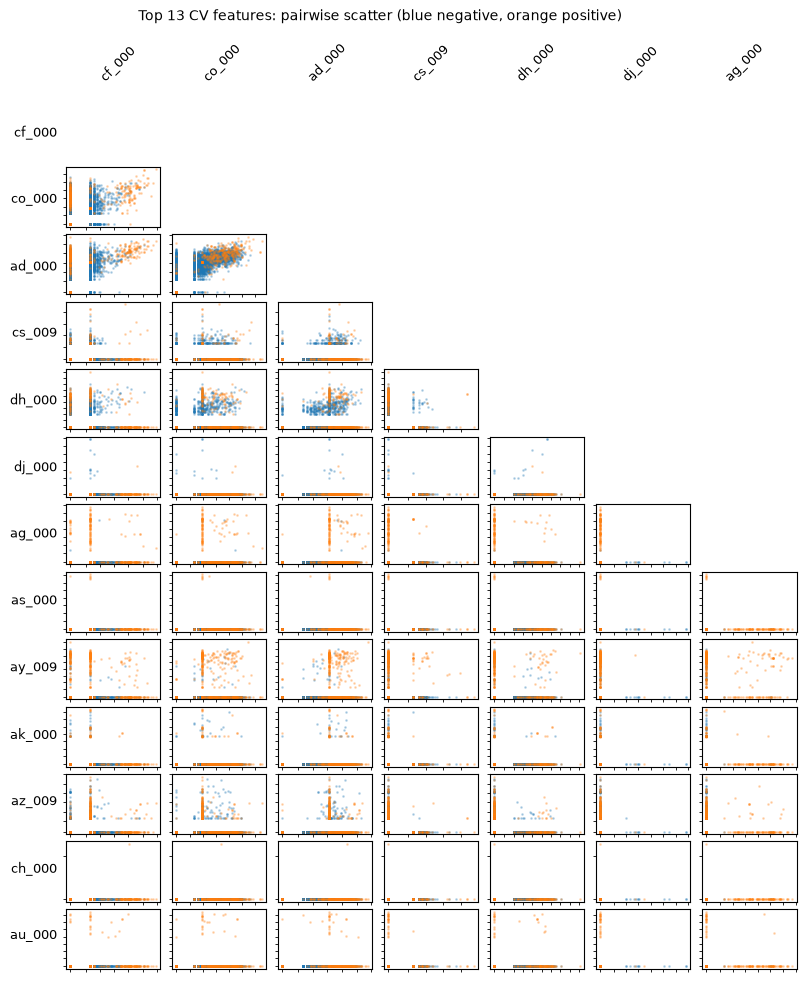

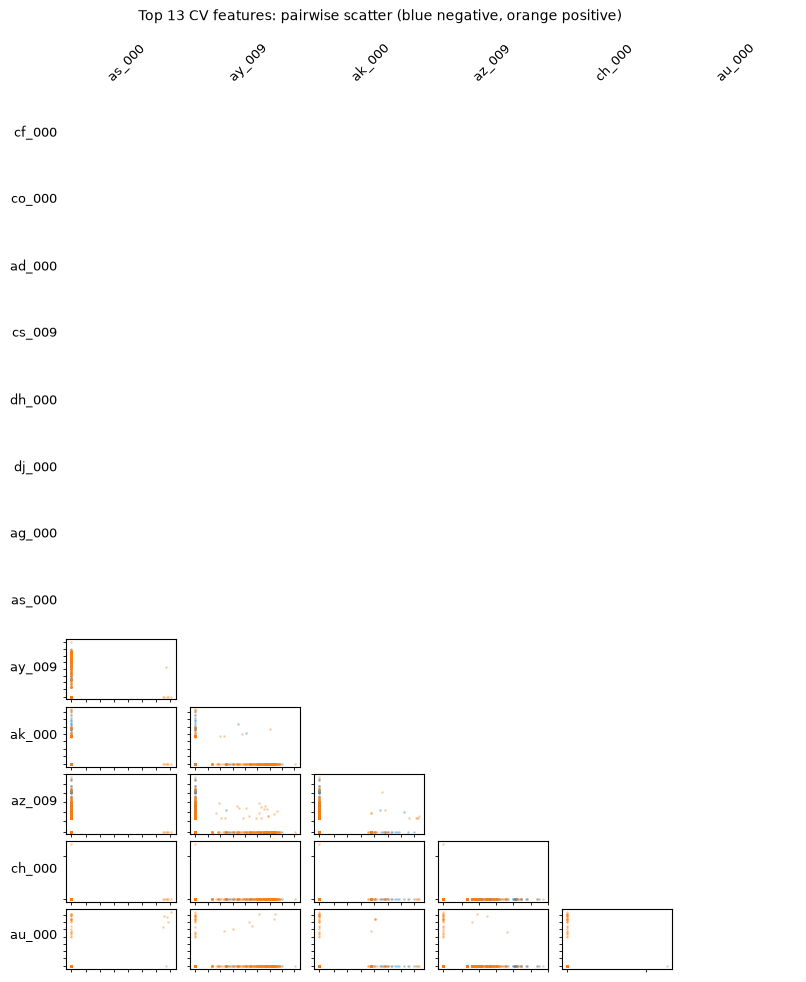

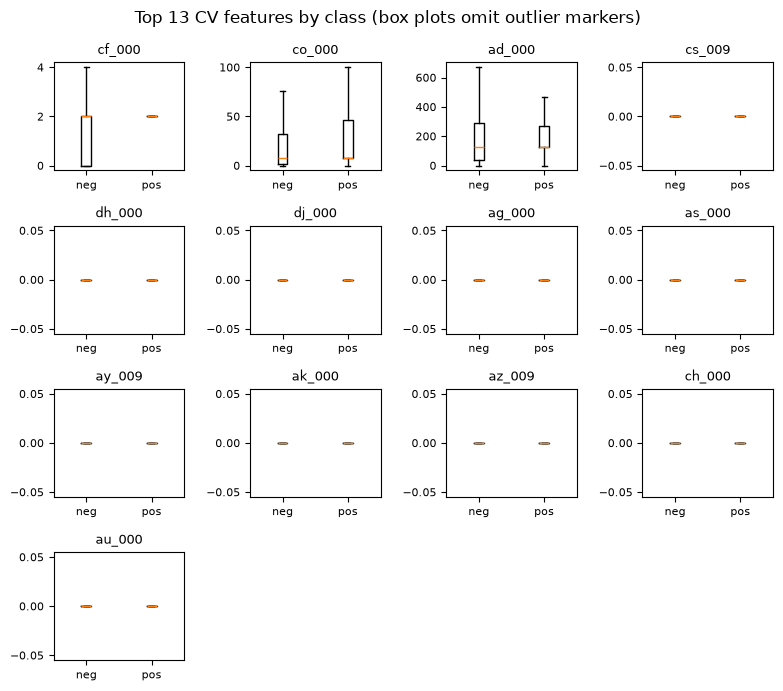

For example, `cs_009` is zero for 56,148/59,000 negatives (95.17%) and 948/1,000 positives (94.8%) after imputation, so those observations overlap on that feature. Scatter plots can reveal separation but cannot establish statistical significance without uncertainty or a formal test. They show all 1,000 positives and 4,000 sampled negatives; models use all data.

In [4]:
# Show every pair among the top 13 CV features in two labeled triangular panels.
# Keep all positives and a reproducible sample of negatives for visual clarity.
rng = np.random.default_rng(SEED)
show_idx = np.r_[np.flatnonzero(y == 1), rng.choice(np.flatnonzero(y == 0), 4000, replace=False)]
top = cv.head(13).index.tolist()
plot_data = filled.iloc[show_idx][top]
for group in [range(0, 7), range(7, 13)]:
    fig, axes = plt.subplots(13, len(group), figsize=(8.5, 10), squeeze=False)
    fig.subplots_adjust(left=.13, right=.99, top=.90, bottom=.03, hspace=.12, wspace=.12)
    for i in range(13):
        for col, j in enumerate(group):
            ax = axes[i, col]
            if i > j:
                for label, color in [(0, 'tab:blue'), (1, 'tab:orange')]:
                    mask = y[show_idx] == label
                    ax.scatter(plot_data.iloc[mask, j], plot_data.iloc[mask, i], c=color, s=1, alpha=.25, rasterized=True)
                ax.set_xscale('symlog', linthresh=1); ax.set_yscale('symlog', linthresh=1)
            else:
                ax.set_axis_off()
            ax.set_xticks([]); ax.set_yticks([])
    for col, j in enumerate(group):
        fig.text(.13+(col+.5)*.86/len(group), .915, top[j], ha='center', va='bottom', fontsize=9, rotation=45)
    for i, name in enumerate(top):
        fig.text(.12, .90-(i+.5)*.87/13, name, ha='right', va='center', fontsize=9)
    fig.suptitle('Top 13 CV features: pairwise scatter (blue negative, orange positive)', fontsize=10, y=.99)
    plt.show()
fig, axes = plt.subplots(4, 4, figsize=(8, 7))
for i, name in enumerate(top):
    ax = axes.flat[i]
    ax.boxplot([filled.loc[y == 0, name], filled.loc[y == 1, name]], showfliers=False, tick_labels=['neg', 'pos'])
    ax.set_title(name, fontsize=9)
    ax.tick_params(labelsize=8)
for ax in axes.flat[13:]: ax.axis('off')
fig.suptitle('Top 13 CV features by class (box plots omit outlier markers)')
plt.tight_layout(); plt.show()
display(Markdown('For example, `cs_009` is zero for 56,148/59,000 negatives (95.17%) and 948/1,000 positives (94.8%) after imputation, so those observations overlap on that feature. Scatter plots can reveal separation but cannot establish statistical significance without uncertainty or a formal test. They show all 1,000 positives and 4,000 sampled negatives; models use all data.'))

## 1(c)–(d) Random forests

A class-weighted forest gives minority-class classification errors greater weight in each split. We use `class_weight="balanced"`, which weights each class inversely to its training frequency. Both forests use the same 50 trees and all observations; out-of-bag (OOB) error uses predictions from trees that did not bootstrap the observation. [scikit-learn RandomForestClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).

In [5]:
models = {}
for name, weight in [('RF', None), ('Weighted RF', 'balanced')]:
    model = RandomForestClassifier(n_estimators=50, n_jobs=4, random_state=SEED,
                                   oob_score=True, class_weight=weight)
    model.fit(X, y)
    models[name] = model
    print(f'{name}: OOB error = {1-model.oob_score_:.5f}')

RF: OOB error = 0.00615


Weighted RF: OOB error = 0.01990


## 1(e)–(f) XGBoost and SMOTE

We select `reg_alpha` from {0, 1, 10} using five-fold stratified CV and misclassification error. XGBoost's `gbtree` is the tree-based alternative specified in 1(e); its L1 penalty applies to leaf weights, so it is not a logistic regression model at each node. For SMOTE, interpolation is done **only on the training part of each fold** before fitting; validation observations are never oversampled. Features are standardized using each training fold before SMOTE distance calculations, then returned to their original units. Resampling the full data before CV would leak synthetic information across folds. The final SMOTE model uses the entire 60,000-row training set. References: [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html), [imbalanced-learn common pitfalls](https://imbalanced-learn.org/stable/common_pitfalls.html).

In [6]:
alphas = [0, 1, 10]
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_errors = {'XGB': {a: [] for a in alphas}, 'SMOTE XGB': {a: [] for a in alphas}}

def xgb(alpha):
    return XGBClassifier(n_estimators=50, max_depth=4, learning_rate=.1,
                         reg_alpha=alpha, objective='binary:logistic',
                         eval_metric='logloss', tree_method='hist',
                         random_state=SEED, n_jobs=4)
for fold, (itr, iva) in enumerate(folds.split(X_raw, y), 1):
    imp = SimpleImputer(strategy='median')
    xf = imp.fit_transform(X_raw.iloc[itr]).astype(np.float32)
    xv = imp.transform(X_raw.iloc[iva]).astype(np.float32)
    yf, yv = y[itr], y[iva]
    scaler = StandardScaler().fit(xf)
    xs, ys = SMOTE(random_state=SEED).fit_resample(scaler.transform(xf), yf)
    xs = scaler.inverse_transform(xs)
    for a in alphas:
        for name, xx, yy in [('XGB', xf, yf), ('SMOTE XGB', xs, ys)]:
            model = xgb(a); model.fit(xx, yy)
            cv_errors[name][a].append(1 - accuracy_score(yv, model.predict(xv)))
    print(f'Completed CV fold {fold}/5', flush=True)
    del xs, ys, xf, xv
cv_table = pd.DataFrame({name: {a: np.mean(v) for a, v in row.items()} for name, row in cv_errors.items()})
cv_table.index.name = 'alpha'
display(cv_table.round(5))
selected = cv_table.idxmin()
print('Selected alpha:', selected.to_dict())
models['XGB'] = xgb(float(selected['XGB'])); models['XGB'].fit(X, y)
scaler = StandardScaler().fit(X)
Xs, ys = SMOTE(random_state=SEED).fit_resample(scaler.transform(X), y)
Xs = scaler.inverse_transform(Xs)
print('Full SMOTE training counts:', dict(zip(*np.unique(ys, return_counts=True))))
models['SMOTE XGB'] = xgb(float(selected['SMOTE XGB'])); models['SMOTE XGB'].fit(Xs, ys)
del Xs, ys

Completed CV fold 1/5


Completed CV fold 2/5


Completed CV fold 3/5


Completed CV fold 4/5


Completed CV fold 5/5


,XGB,SMOTE XGB
alpha,,
0,0.00777,0.02558
1,0.00773,0.02582
10,0.00882,0.02663


Selected alpha: {'XGB': 1, 'SMOTE XGB': 0}


Full SMOTE training counts: {np.int64(0): np.int64(59000), np.int64(1): np.int64(59000)}


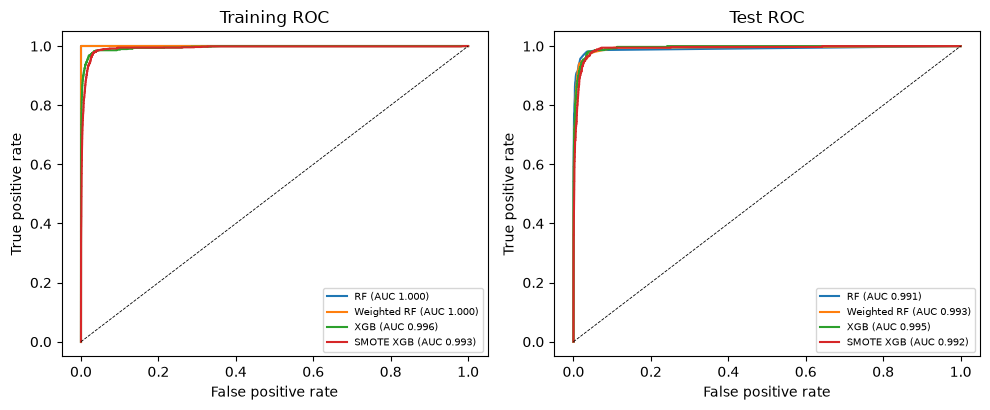

TN    FP   FN    TP      AUC    Error
Model       Split                                          
RF          Train  59000     0    4   996  1.00000  0.00007
            Test   15609    16  112   263  0.99062  0.00800
Weighted RF Train  58980    20    0  1000  1.00000  0.00033
            Test   15569    56  100   275  0.99267  0.00975
XGB         Train  58938    62  238   762  0.99552  0.00500
            Test   15602    23  120   255  0.99481  0.00894
SMOTE XGB   Train  57506  1494   44   956  0.99311  0.02563
            Test   15188   437   19   356  0.99157  0.02850

Each confusion matrix is [[TN, FP], [FN, TP]]; error is (FP + FN)/total.


**1(c)–(d).** RF OOB error 0.0061 vs test error 0.0080; weighted RF OOB error 0.0199 vs test error 0.0098. The weighted forest has 100 false negatives and 56 false positives, versus 112 and 16 for the unweighted forest; its test AUC is 0.9927 versus 0.9906.

**1(e)–(f).** Uncompensated XGBoost selected alpha 1 with CV error 0.0077 and test error 0.0089; SMOTE XGBoost selected alpha 0 with CV error 0.0256 and test error 0.0285. On test data, SMOTE changes false negatives from 120 to 19, false positives from 23 to 437, and AUC from 0.9948 to 0.9916.

In [7]:
results = []
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for name, model in models.items():
    for split, values, target, ax in [('Train', X, y, axes[0]), ('Test', T, yt, axes[1])]:
        pred = model.predict(values)
        prob = model.predict_proba(values)[:,1]
        tn, fp, fn, tp = confusion_matrix(target, pred, labels=[0,1]).ravel()
        auc = roc_auc_score(target, prob)
        error = 1-accuracy_score(target, pred)
        results.append([name, split, tn, fp, fn, tp, auc, error])
        fpr, tpr, _ = roc_curve(target, prob)
        ax.plot(fpr, tpr, label=f'{name} (AUC {auc:.3f})')
for ax, title in zip(axes, ['Training ROC', 'Test ROC']):
    ax.plot([0,1], [0,1], 'k--', lw=.6); ax.set(xlabel='False positive rate', ylabel='True positive rate', title=title)
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
metrics = pd.DataFrame(results, columns=['Model','Split','TN','FP','FN','TP','AUC','Error']).set_index(['Model','Split'])
display(metrics.round(5))
print('Each confusion matrix is [[TN, FP], [FN, TP]]; error is (FP + FN)/total.')
r = metrics.loc[('RF','Test')]; w = metrics.loc[('Weighted RF','Test')]
display(Markdown(f"**1(c)–(d).** RF OOB error {1-models['RF'].oob_score_:.4f} vs test error {r.Error:.4f}; weighted RF OOB error {1-models['Weighted RF'].oob_score_:.4f} vs test error {w.Error:.4f}. The weighted forest has {int(w.FN)} false negatives and {int(w.FP)} false positives, versus {int(r.FN)} and {int(r.FP)} for the unweighted forest; its test AUC is {w.AUC:.4f} versus {r.AUC:.4f}."))
a = metrics.loc[('XGB','Test')]; b = metrics.loc[('SMOTE XGB','Test')]
display(Markdown(f"**1(e)–(f).** Uncompensated XGBoost selected alpha {selected['XGB']} with CV error {cv_table.loc[selected['XGB'],'XGB']:.4f} and test error {a.Error:.4f}; SMOTE XGBoost selected alpha {selected['SMOTE XGB']} with CV error {cv_table.loc[selected['SMOTE XGB'],'SMOTE XGB']:.4f} and test error {b.Error:.4f}. On test data, SMOTE changes false negatives from {int(a.FN)} to {int(b.FN)}, false positives from {int(a.FP)} to {int(b.FP)}, and AUC from {a.AUC:.4f} to {b.AUC:.4f}."))

For the unweighted forest, OOB error (0.615%) is below test error (0.800%); for the weighted forest, OOB error (1.990%) is above test error (0.975%), and weighting reduces false negatives from 112 to 100 while increasing false positives from 16 to 56 and overall test error.

Both XGBoost CV errors are below their test errors; SMOTE reduces false negatives from 120 to 19 but increases false positives from 23 to 437 and raises test error from 0.894% to 2.850%.

## 2. ISLR 6.6.3
(a) **iv**: training RSS is nonincreasing as the L1 constraint expands. (b) **ii**: test RSS typically falls then rises as bias decreases and variance increases. (c) **iii**: variance generally increases. (d) **iv**: squared bias generally decreases. (e) **v**: irreducible error remains constant. These describe the usual bias–variance pattern, not a guaranteed test curve for every dataset.

## 3. ISLR 6.6.5
Let $x_{11}=x_{12}=a$, $x_{21}=x_{22}=-a$, $y_1=b$, and $y_2=-b$, with zero intercept.

(a) Ridge minimizes $2[b-a(\beta_1+\beta_2)]^2+\lambda(\beta_1^2+\beta_2^2)$.

(b) For a fixed sum $t=\beta_1+\beta_2$, the penalty equals $t^2/2+(\beta_1-\beta_2)^2/2$, so for $\lambda>0$ it is uniquely minimized at $\beta_1=\beta_2$.

(c) Lasso minimizes $2[b-a(\beta_1+\beta_2)]^2+\lambda(|\beta_1|+|\beta_2|)$.

(d) For a nonzero optimal sum $t^*$, every same-sign split summing to $t^*$ has the same RSS and minimum penalty $|t^*|$, yielding infinitely many solutions. If $t^*=0$ and $\lambda>0$, only $(0,0)$ minimizes the penalty.

## 4. ISLR 8.4.5
Six of ten probabilities exceed 0.5, so majority vote predicts **Red** (6–4). The mean probability is $4.5/10=0.45$, so averaging probabilities predicts **Green**.

## 5. ISLR 9.7.3
(a) The observations are plotted below. (b) The maximum-margin separator is $x_2=x_1-0.5$. (c) Predict Red if $0.5-x_1+x_2>0$, Blue otherwise; $(\beta_0,\beta_1,\beta_2)=(0.5,-1,1)$. (d) The margins are $x_2=x_1$ and $x_2=x_1-1$, at distance $1/(2\sqrt{2})$ from the separator. (e) Support vectors are Red $(2,2),(4,4)$ and Blue $(2,1),(4,3)$.

(f) The Blue point $(4,1)$ lies strictly outside the margin, so a sufficiently small movement does not change the separator. (g) $x_2=x_1-0.25$ also separates the data but has a smaller margin. (h) A new Blue point $(3,3)$ lies on the segment between the Red points $(2,2)$ and $(4,4)$, making linear separation impossible.

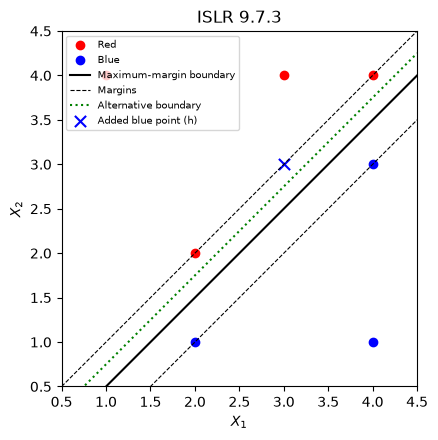

In [8]:
red = np.array([[3,4],[2,2],[4,4],[1,4]])
blue = np.array([[2,1],[4,3],[4,1]])
xline = np.linspace(.5, 4.5, 100)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(*red.T, color='red', label='Red'); ax.scatter(*blue.T, color='blue', label='Blue')
ax.plot(xline, xline-.5, 'k-', label='Maximum-margin boundary')
ax.plot(xline, xline, 'k--', lw=.8, label='Margins')
ax.plot(xline, xline-1, 'k--', lw=.8)
ax.plot(xline, xline-.25, color='green', ls=':', label='Alternative boundary')
ax.scatter([3], [3], marker='x', color='blue', s=65, label='Added blue point (h)')
ax.set(xlim=(.5,4.5), ylim=(.5,4.5), xlabel='$X_1$', ylabel='$X_2$', title='ISLR 9.7.3'); ax.set_aspect('equal'); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()